# Результаты: RAG-ассистент по законодательству о защите прав потребителей

Ноутбук только читает готовые результаты из `../results/` и `../data/` (запросы к API здесь не выполняются).
Эксперименты запускаются скриптами `src/run_retrieval.py` и `src/run_generation.py`, подробности в README.

Это учебный проект, а не юридическая консультация. Оценочный набор составлен моделями (формальные вопросы по тексту статей,
разговорные написаны ассистентом-LLM) и **не проверен человеком** (`verified_by_human = False`). Цифры показывают сравнительное
качество вариантов, а не абсолютную точность системы.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
R, D = ROOT / "results", ROOT / "data"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

meta = json.loads((D / "corpus_meta.json").read_text(encoding="utf-8"))
ev = pd.read_csv(D / "eval_set.csv")
print(f"Корпус: {meta['total_articles']} статей, {meta['total_chars']:,} символов; загружен {meta['retrieved']}")
for k, v in meta["sources"].items():
    print(f"  {k}: версия страницы Викитеки от {v['revision_timestamp']}, статей {v['articles']}")
print(f"Оценочный набор: {len(ev)} вопросов; проверено человеком: {int(ev.verified_by_human.sum())}")
display(ev.groupby(["subset", "answerable"]).size().rename("вопросов").to_frame())
display(ev[ev.subset == "colloquial"][["qid", "question", "gold_article_id", "gold_article_id_2"]])

Корпус: 65 статей, 117,332 символов; загружен 2026-11-21
  zpp: версия страницы Викитеки от 2023-12-30T10:36:54Z, статей 51
  gk: версия страницы Викитеки от 2025-08-30T03:50:36Z, статей 14
Оценочный набор: 72 вопросов; проверено человеком: 20


вопросов
subset     answerable          
colloquial True              18
formal     False             10
           True              44

,qid,question,gold_article_id,gold_article_id_2
54,q55,"Купил телефон, через неделю сломался. Что мне делать и когда вернут деньги, если я их потребую?",zpp:18,zpp:22
55,q56,"Магазин не берёт назад кроссовки, не подошли по размеру. Они вправе отказать?",zpp:25,gk:502
56,q57,"кароч заказал на озоне кросы, пришли мелкие, вернуть можна и сколько на это дней?",zpp:26.1,NaN
57,q58,"Пылесос куплен 14 месяцев назад, гарантии на нём нет, и он сломался. Я ещё могу что-то требовать от продавца?",zpp:19,NaN
58,q59,"В магазине сказали: чек потеряли, значит, ничего не вернём и не заменим. Это законно?",zpp:18,zpp:25
59,q60,"Принёс сломанный чайник в магазин, а мне говорят: идите в сервис к производителю, это не наше дело. Они пр...",zpp:18,NaN
60,q61,"Бригада затягивает ремонт кухни, срок давно прошёл. Что я могу потребовать?",zpp:28,NaN
61,q62,"Телевизор в ремонте уже два месяца, мастер всё твердит: ещё недельку. Сколько его вообще могут чинить?",zpp:20,NaN
62,q63,"Заплатил сайту предоплату за стиральную машину, а её не везут уже месяц. Что мне делать?",zpp:23.1,NaN
63,q64,"Записался в фитнес-клуб на год, а через месяц передумал. Можно выйти из договора и вернут ли деньги?",zpp:32,NaN


## 1. Поиск: чанкинг × поисковик, по подмножествам

hit@k: среди первых k чанков есть чанк эталонной статьи (для вопросов с двумя эталонными статьями засчитывается любая); MRR по первому такому чанку. Подмножества: `formal` (вопросы по тексту статей, 44) и `colloquial` (разговорные, 18).

In [2]:
s = pd.read_csv(R / "retrieval_summary.csv")
order = ["bm25", "tfidf_char", "dense_small", "dense_large", "hybrid_small", "hybrid_large", "bm25+rerank", "dense_large+rerank"]
chunk_order = ["article", "part", "win500", "win1000"]
display(s.drop_duplicates("chunking").set_index("chunking")[["n_chunks", "avg_chunk_chars"]].loc[chunk_order])
for subset in ("formal", "colloquial", "all"):
    print(f"\nMRR, подмножество {subset}")
    display(s[s.subset == subset].pivot(index="retriever", columns="chunking", values="mrr").loc[order, chunk_order].round(3))

,n_chunks,avg_chunk_chars
chunking,,
article,65,1895
part,181,749
win500,316,546
win1000,166,924



MRR, подмножество formal


chunking,article,part,win500,win1000
retriever,,,,
bm25,0.760,0.774,0.777,0.780
tfidf_char,0.796,0.806,0.863,0.832
dense_small,0.948,0.963,0.952,0.964
dense_large,0.972,0.984,0.966,0.988
hybrid_small,0.878,0.906,0.905,0.954
hybrid_large,0.896,0.916,0.908,0.944
bm25+rerank,0.969,0.976,0.960,0.976
dense_large+rerank,0.956,1.000,0.988,1.000



MRR, подмножество colloquial


chunking,article,part,win500,win1000
retriever,,,,
bm25,0.211,0.230,0.304,0.237
tfidf_char,0.281,0.263,0.252,0.270
dense_small,0.789,0.774,0.838,0.833
dense_large,0.858,0.971,0.882,0.931
hybrid_small,0.540,0.451,0.541,0.570
hybrid_large,0.501,0.615,0.591,0.540
bm25+rerank,0.691,0.618,0.618,0.637
dense_large+rerank,0.926,1.000,0.971,0.961



MRR, подмножество all


chunking,article,part,win500,win1000
retriever,,,,
bm25,0.602,0.617,0.640,0.624
tfidf_char,0.648,0.649,0.687,0.670
dense_small,0.902,0.909,0.920,0.927
dense_large,0.939,0.980,0.942,0.972
hybrid_small,0.781,0.775,0.800,0.844
hybrid_large,0.782,0.829,0.816,0.828
bm25+rerank,0.889,0.873,0.862,0.878
dense_large+rerank,0.947,1.000,0.983,0.989


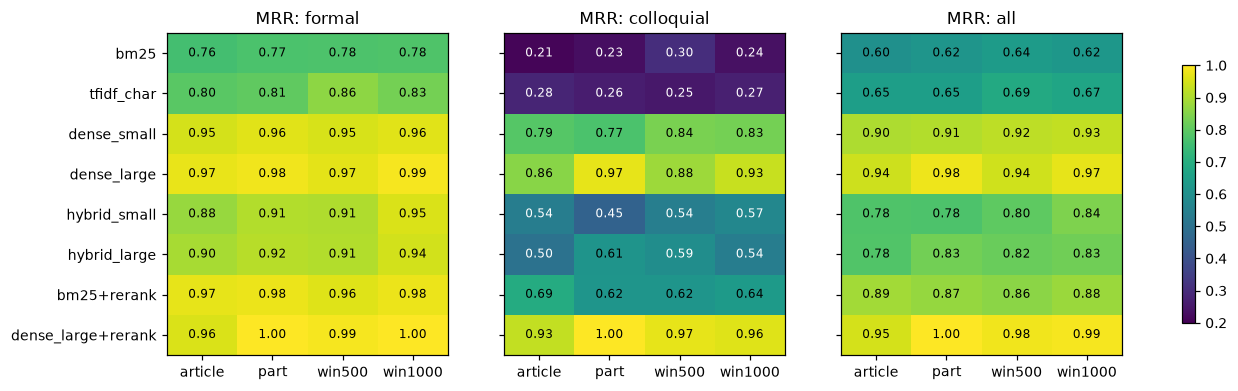

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, subset in zip(axes, ("formal", "colloquial", "all")):
    mat = s[s.subset == subset].pivot(index="retriever", columns="chunking", values="mrr").loc[order, chunk_order]
    im = ax.imshow(mat.values, cmap="viridis", vmin=0.2, vmax=1.0, aspect="auto")
    ax.set_xticks(range(len(chunk_order)), chunk_order)
    ax.set_yticks(range(len(order)), order)
    ax.set_title(f"MRR: {subset}")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", color="white" if mat.values[i, j] < 0.6 else "black", fontsize=8)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### Где методы расходятся: разговорные вопросы

На формальных вопросах почти все плотные конфигурации упираются в потолок (hit@3 около 1.0). Разговорные вопросы почти не пересекаются по лексике со статьями, и методы разделяются. Интервалы бутстрэпа (95%, по 18 вопросам) широкие: при отсутствии промахов интервал вырождается в точку, это не доказательство безошибочности.

In [4]:
cols = ["chunking", "retriever", "hit@1", "hit@1_lo", "hit@1_hi", "hit@3", "hit@3_lo", "hit@3_hi", "mrr", "mrr_lo", "mrr_hi"]
col = s[(s.subset == "colloquial") & (s.chunking == "part")].set_index("retriever").loc[order].reset_index()
display(col[["retriever"] + cols[2:]].round(3))

,retriever,hit@1,hit@1_lo,hit@1_hi,hit@3,hit@3_lo,hit@3_hi,mrr,mrr_lo,mrr_hi
0,bm25,0.118,0.000,0.294,0.294,0.118,0.529,0.230,0.095,0.394
1,tfidf_char,0.118,0.000,0.294,0.294,0.118,0.529,0.263,0.129,0.413
2,dense_small,0.647,0.412,0.882,0.882,0.706,1.000,0.774,0.616,0.916
3,dense_large,0.941,0.824,1.000,1.000,1.000,1.000,0.971,0.912,1.000
4,hybrid_small,0.235,0.059,0.471,0.647,0.412,0.882,0.451,0.308,0.610
5,hybrid_large,0.412,0.176,0.647,0.824,0.647,1.000,0.615,0.458,0.773
6,bm25+rerank,0.588,0.353,0.824,0.647,0.412,0.882,0.618,0.412,0.824
7,dense_large+rerank,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


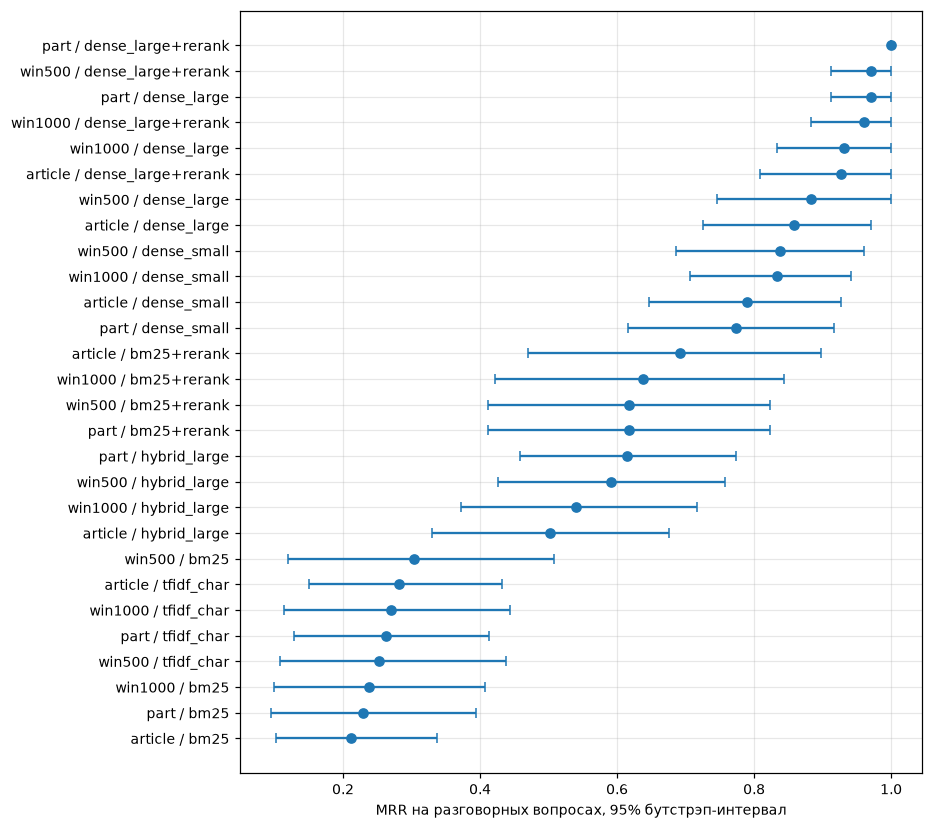

In [5]:
sel = s[(s.subset == "colloquial") & s.retriever.isin(["bm25", "tfidf_char", "dense_small", "dense_large", "hybrid_large", "bm25+rerank", "dense_large+rerank"])].copy()
sel["label"] = sel.chunking + " / " + sel.retriever
sel = sel.sort_values("mrr")
fig, ax = plt.subplots(figsize=(8, 9))
ax.errorbar(sel.mrr, range(len(sel)), xerr=[sel.mrr - sel.mrr_lo, sel.mrr_hi - sel.mrr], fmt="o", capsize=3)
ax.set_yticks(range(len(sel)), sel.label)
ax.set_xlabel("MRR на разговорных вопросах, 95% бутстрэп-интервал")
plt.show()

In [6]:
pq = pd.read_csv(R / "retrieval_per_question.csv")
two = pq[(pq.chunking == "part") & pq.both_gold_in_top5.notna()]
print("Вопросы с двумя эталонными статьями (разговорные): обе статьи среди первых 5 чанков, чанкинг part")
display(two.groupby("retriever").both_gold_in_top5.mean().round(2).rename("доля").to_frame().loc[order])

Вопросы с двумя эталонными статьями (разговорные): обе статьи среди первых 5 чанков, чанкинг part


,доля
retriever,
bm25,0.0
tfidf_char,0.0
dense_small,0.2
dense_large,0.6
hybrid_small,0.2
hybrid_large,0.2
bm25+rerank,0.4
dense_large+rerank,0.6


### Задержка API (медиана из 5 вызовов с уникальными запросами)

In [7]:
pd.read_csv(R / "api_latency.csv")

,step,model,median_s,n
0,embed_small,am/nemotron-3-embed-1b,0.923,5
1,embed_large,am/nemotron-3.5-embed-8b,2.274,5
2,rerank_top20,am/nemotron-3.5-rerank-8b,2.355,5


### Разбор ошибок поиска (чанкинг part)

In [8]:
evq = ev.set_index("qid")
def fails(retriever, subset, min_rank, chunking="part"):
    sub = pq[(pq.chunking == chunking) & (pq.retriever == retriever) & (pq.subset == subset) & (pq.first_gold_rank > min_rank)].copy()
    sub["вопрос"] = sub.qid.map(evq.question)
    return sub[["qid", "gold_article_id", "first_gold_rank", "top5_articles", "вопрос"]]
print("dense_large, формальные, эталон не на 1-м месте:")
display(fails("dense_large", "formal", 1))
print("dense_large, разговорные, эталон не на 1-м месте:")
display(fails("dense_large", "colloquial", 1))
print("bm25, разговорные, эталон ниже 3-го места (первые 8):")
display(fails("bm25", "colloquial", 3).head(8))

dense_large, формальные, эталон не на 1-м месте:


,qid,gold_article_id,first_gold_rank,top5_articles,вопрос
654,q06,zpp:10,3,gk:495|zpp:26.1|zpp:10|zpp:10|zpp:8,Какие сроки и связанную с ними информацию продавец обязан сообщить мне при покупке товара?


dense_large, разговорные, эталон не на 1-м месте:


,qid,gold_article_id,first_gold_rank,top5_articles,вопрос
696,q60,zpp:18,2,zpp:5|zpp:18|zpp:18|zpp:5|zpp:5,"Принёс сломанный чайник в магазин, а мне говорят: идите в сервис к производителю, это не наше дело. Они пр..."


bm25, разговорные, эталон ниже 3-го места (первые 8):


,qid,gold_article_id,first_gold_rank,top5_articles,вопрос
514,q55,zpp:18|zpp:22,13,gk:494|zpp:29|zpp:19|zpp:19|zpp:13,"Купил телефон, через неделю сломался. Что мне делать и когда вернут деньги, если я их потребую?"
516,q57,zpp:26.1,10,zpp:21|zpp:19|zpp:28|zpp:29|zpp:33,"кароч заказал на озоне кросы, пришли мелкие, вернуть можна и сколько на это дней?"
519,q60,zpp:18,9,zpp:40|zpp:45|zpp:4|zpp:19|zpp:40,"Принёс сломанный чайник в магазин, а мне говорят: идите в сервис к производителю, это не наше дело. Они пр..."
520,q61,zpp:28,12,zpp:20|zpp:6|zpp:29|zpp:20|zpp:18,"Бригада затягивает ремонт кухни, срок давно прошёл. Что я могу потребовать?"
521,q62,zpp:20,13,zpp:6|zpp:33|zpp:18|gk:494|zpp:26.1,"Телевизор в ремонте уже два месяца, мастер всё твердит: ещё недельку. Сколько его вообще могут чинить?"
522,q63,zpp:23.1,24,zpp:29|zpp:4|zpp:36|gk:495|zpp:26.1,"Заплатил сайту предоплату за стиральную машину, а её не везут уже месяц. Что мне делать?"
523,q64,zpp:32,84,zpp:26.1|zpp:9|zpp:46|zpp:16.1|zpp:9,"Записался в фитнес-клуб на год, а через месяц передумал. Можно выйти из договора и вернут ли деньги?"
524,q65,zpp:33,30,zpp:13|zpp:24|zpp:7|zpp:18|zpp:5,"Прораб назвал смету сто тысяч, а теперь говорит, что вышло намного дороже. Я обязан доплачивать?"


## 2. Генерация: промпты, контроль без поиска, k = 3

Генератор `LLM_MODEL` (бесплатная модель среднего размера с рассуждениями), температура 0.0, 3 контекста (k = 3). Ответы оценивают **две** модели одной рубрикой при T = 0:
`j1` = `ag/gemini-3-flash` (основной, выбран за скорость около 2 с на вызов), `j2` = `am/laguna-xs-2.1` (другое семейство, без рассуждений).
Кросс-проверка `j3` = `am/nemotron-3-ultra-550b-a55b` (медленная большая модель того же семейства, что и генератор) выполнена только на ответах на проверенные человеком вопросы лучшей конфигурации.
Рубрика: correctness 0-2 относительно эталона, faithful (все утверждения подтверждены фрагментами), abstained (отказ). Для контроля без поиска верность не определена (n/a).
`cites_gold` считается программно (упомянута ли в ответе эталонная статья).

In [9]:
g = pd.read_csv(R / "generation_summary.csv")
g["config"] = g.chunking + " / " + g.retriever
headline = (R / "headline_judge.txt").read_text().strip() if (R / "headline_judge.txt").exists() else "j1"
print("Основной оценщик (лучше согласуется с ручными метками):", headline)
show = ["config", "prompt", "n_answerable", "correct_full_rate", "correct_full_lo", "correct_full_hi", "correct_mean_0_2", "faithful_rate",
        "false_abstain_rate", "abstain_correct_rate", "cites_gold_rate", "gold_in_context_rate", "avg_context_chars", "avg_answer_chars"]
for j in ("j1", "j2"):
    for subset in ("all", "formal", "colloquial"):
        print(f"\nОценщик {j}: {g[g.judge == j].judge_model.iloc[0]}; подмножество {subset}" + ("  <- основной" if j == headline else ""))
        display(g[(g.judge == j) & (g.subset == subset)][show].reset_index(drop=True))

Основной оценщик (лучше согласуется с ручными метками): j1

Оценщик j1: ag/gemini-3-flash; подмножество all  <- основной


,config,prompt,n_answerable,correct_full_rate,correct_full_lo,correct_full_hi,correct_mean_0_2,faithful_rate,false_abstain_rate,abstain_correct_rate,cites_gold_rate,gold_in_context_rate,avg_context_chars,avg_answer_chars
0,part / dense_large+rerank,naive,59,0.966,0.915,1.000,1.949,0.957,0.000,0.8,0.492,1.000,2567,649
1,part / dense_large+rerank,strict,59,0.864,0.780,0.949,1.847,0.942,0.034,0.9,0.966,1.000,2567,209
2,part / dense_large+rerank,strict_fewshot,59,0.712,0.593,0.831,1.661,0.942,0.034,0.9,0.881,1.000,2567,176
3,win500 / tfidf_char,naive,59,0.627,0.508,0.746,1.458,0.739,0.017,0.8,0.153,0.746,1637,473
4,win500 / tfidf_char,strict,59,0.525,0.390,0.661,1.241,0.942,0.237,0.9,0.610,0.746,1637,138
5,win500 / tfidf_char,strict_fewshot,59,0.508,0.373,0.627,1.207,0.942,0.271,1.0,0.593,0.746,1637,118
6,- / none,no_context,59,0.458,0.339,0.593,1.051,NaN,0.017,0.4,0.085,NaN,0,2045



Оценщик j1: ag/gemini-3-flash; подмножество formal  <- основной


,config,prompt,n_answerable,correct_full_rate,correct_full_lo,correct_full_hi,correct_mean_0_2,faithful_rate,false_abstain_rate,abstain_correct_rate,cites_gold_rate,gold_in_context_rate,avg_context_chars,avg_answer_chars
0,part / dense_large+rerank,naive,42,0.952,0.881,1.000,1.929,0.942,0.000,0.8,0.357,1.000,2527,459
1,part / dense_large+rerank,strict,42,0.905,0.810,0.976,1.881,0.962,0.024,0.9,0.976,1.000,2527,189
2,part / dense_large+rerank,strict_fewshot,42,0.810,0.690,0.905,1.762,0.981,0.048,0.9,0.905,1.000,2527,159
3,win500 / tfidf_char,naive,42,0.738,0.595,0.881,1.643,0.846,0.024,0.8,0.143,0.929,1662,364
4,win500 / tfidf_char,strict,42,0.667,0.524,0.810,1.561,0.942,0.143,0.9,0.786,0.929,1662,141
5,win500 / tfidf_char,strict_fewshot,42,0.667,0.524,0.810,1.500,0.962,0.143,1.0,0.738,0.929,1662,130
6,- / none,no_context,42,0.405,0.262,0.548,0.952,NaN,0.024,0.4,0.024,NaN,0,1472



Оценщик j1: ag/gemini-3-flash; подмножество colloquial  <- основной


,config,prompt,n_answerable,correct_full_rate,correct_full_lo,correct_full_hi,correct_mean_0_2,faithful_rate,false_abstain_rate,abstain_correct_rate,cites_gold_rate,gold_in_context_rate,avg_context_chars,avg_answer_chars
0,part / dense_large+rerank,naive,17,1.000,1.000,1.000,2.000,1.000,0.000,NaN,0.824,1.000,2687,1228
1,part / dense_large+rerank,strict,17,0.765,0.529,0.941,1.765,0.882,0.059,NaN,0.941,1.000,2687,268
2,part / dense_large+rerank,strict_fewshot,17,0.471,0.235,0.706,1.412,0.824,0.000,NaN,0.824,1.000,2687,229
3,win500 / tfidf_char,naive,17,0.353,0.118,0.588,1.000,0.412,0.000,NaN,0.176,0.294,1561,807
4,win500 / tfidf_char,strict,17,0.176,0.000,0.353,0.471,0.941,0.471,NaN,0.176,0.294,1561,129
5,win500 / tfidf_char,strict_fewshot,17,0.118,0.000,0.294,0.438,0.882,0.588,NaN,0.235,0.294,1561,83
6,- / none,no_context,17,0.588,0.353,0.824,1.294,NaN,0.000,NaN,0.235,NaN,0,3798


... (2 outputs left out)


Оценщик j2: am/laguna-xs-2.1; подмножество formal


,config,prompt,n_answerable,correct_full_rate,correct_full_lo,correct_full_hi,correct_mean_0_2,faithful_rate,false_abstain_rate,abstain_correct_rate,cites_gold_rate,gold_in_context_rate,avg_context_chars,avg_answer_chars
0,part / dense_large+rerank,naive,42,0.929,0.833,1.000,1.929,0.904,0.000,0.8,0.357,1.000,2527,459
1,part / dense_large+rerank,strict,42,0.929,0.833,1.000,1.929,0.923,0.024,0.9,0.976,1.000,2527,189
2,part / dense_large+rerank,strict_fewshot,42,0.833,0.714,0.929,1.810,0.942,0.024,0.9,0.905,1.000,2527,159
3,win500 / tfidf_char,naive,42,0.833,0.714,0.929,1.762,0.827,0.000,0.8,0.143,0.929,1662,364
4,win500 / tfidf_char,strict,42,0.619,0.476,0.762,1.500,0.769,0.119,0.9,0.786,0.929,1662,141
5,win500 / tfidf_char,strict_fewshot,42,0.619,0.476,0.762,1.476,0.731,0.119,1.0,0.738,0.929,1662,130
6,- / none,no_context,42,0.429,0.286,0.595,1.119,NaN,0.048,0.6,0.024,NaN,0,1472



Оценщик j2: am/laguna-xs-2.1; подмножество colloquial


,config,prompt,n_answerable,correct_full_rate,correct_full_lo,correct_full_hi,correct_mean_0_2,faithful_rate,false_abstain_rate,abstain_correct_rate,cites_gold_rate,gold_in_context_rate,avg_context_chars,avg_answer_chars
0,part / dense_large+rerank,naive,17,1.000,1.000,1.000,2.000,1.000,0.000,NaN,0.824,1.000,2687,1228
1,part / dense_large+rerank,strict,17,0.765,0.588,0.941,1.765,0.941,0.059,NaN,0.941,1.000,2687,268
2,part / dense_large+rerank,strict_fewshot,17,0.647,0.412,0.882,1.588,0.941,0.059,NaN,0.824,1.000,2687,229
3,win500 / tfidf_char,naive,17,0.412,0.176,0.647,1.176,0.412,0.000,NaN,0.176,0.294,1561,807
4,win500 / tfidf_char,strict,17,0.176,0.000,0.353,0.471,0.176,0.412,NaN,0.176,0.294,1561,129
5,win500 / tfidf_char,strict_fewshot,17,0.000,0.000,0.000,0.294,0.118,0.471,NaN,0.235,0.294,1561,83
6,- / none,no_context,17,0.765,0.529,0.941,1.765,NaN,0.118,NaN,0.235,NaN,0,3798


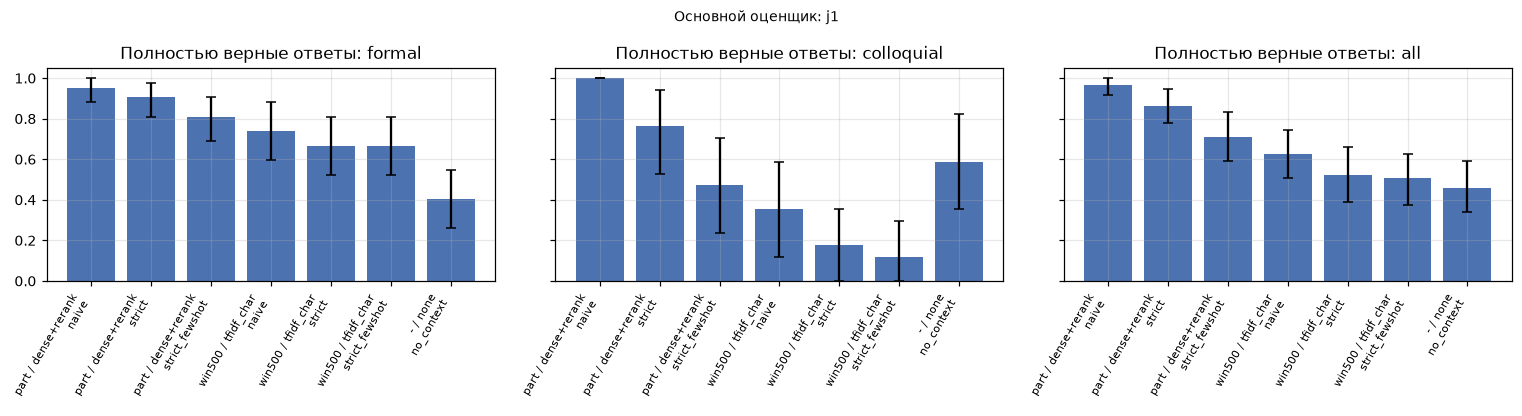

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, subset in zip(axes, ("formal", "colloquial", "all")):
    d = g[(g.judge == headline) & (g.subset == subset)].reset_index(drop=True)
    x = np.arange(len(d))
    cf = pd.to_numeric(d.correct_full_rate)
    ax.bar(x, cf, yerr=[cf - pd.to_numeric(d.correct_full_lo), pd.to_numeric(d.correct_full_hi) - cf], capsize=3, color="#4c72b0")
    ax.set_xticks(x, (d.config.str.replace("dense_large+rerank", "dense+rerank") + "\n" + d.prompt).tolist(), rotation=60, ha="right", fontsize=7)
    ax.set_title(f"Полностью верные ответы: {subset}")
    ax.set_ylim(0, 1.05)
plt.suptitle(f"Основной оценщик: {headline}", fontsize=9)
plt.tight_layout()
plt.show()

## 3. Абляция по числу контекстов k (лучшая конфигурация поиска, лучший промпт)

Задержка измерена прямыми вызовами без кэша на одних и тех же 6 вопросах (медиана), поэтому она грубая.

In [11]:
ka = pd.read_csv(R / "k_ablation.csv")
cols = ["top_k", "correct_full_rate", "correct_mean_0_2", "faithful_rate", "abstain_correct_rate", "false_abstain_rate", "gold_in_context_rate",
        "avg_context_chars", "avg_prompt_tokens", "latency_median_s"]
for j in ("j1", "j2"):
    for subset in ("all", "colloquial"):
        print(f"\nОценщик {j}, подмножество {subset}")
        display(ka[(ka.judge == j) & (ka.subset == subset)][cols].reset_index(drop=True))


Оценщик j1, подмножество all


,top_k,correct_full_rate,correct_mean_0_2,faithful_rate,abstain_correct_rate,false_abstain_rate,gold_in_context_rate,avg_context_chars,avg_prompt_tokens,latency_median_s
0,1,0.881,1.864,0.899,0.8,0.000,1.0,969,369,3.58
1,3,0.966,1.949,0.957,0.8,0.000,1.0,2567,836,5.19
2,5,0.949,1.949,0.971,0.8,0.017,1.0,4222,1316,4.87



Оценщик j1, подмножество colloquial


,top_k,correct_full_rate,correct_mean_0_2,faithful_rate,abstain_correct_rate,false_abstain_rate,gold_in_context_rate,avg_context_chars,avg_prompt_tokens,latency_median_s
0,1,0.765,1.706,0.765,NaN,0.0,1.0,1041,391,3.58
1,3,1.000,2.000,1.000,NaN,0.0,1.0,2687,875,5.19
2,5,1.000,2.000,1.000,NaN,0.0,1.0,4452,1382,4.87



Оценщик j2, подмножество all


,top_k,correct_full_rate,correct_mean_0_2,faithful_rate,abstain_correct_rate,false_abstain_rate,gold_in_context_rate,avg_context_chars,avg_prompt_tokens,latency_median_s
0,1,0.966,1.966,0.957,0.8,0.017,1.0,969,369,3.58
1,3,0.949,1.949,0.928,0.8,0.000,1.0,2567,836,5.19
2,5,0.983,1.983,0.971,0.8,0.017,1.0,4222,1316,4.87



Оценщик j2, подмножество colloquial


,top_k,correct_full_rate,correct_mean_0_2,faithful_rate,abstain_correct_rate,false_abstain_rate,gold_in_context_rate,avg_context_chars,avg_prompt_tokens,latency_median_s
0,1,0.941,1.941,0.941,NaN,0.0,1.0,1041,391,3.58
1,3,1.000,2.000,1.000,NaN,0.0,1.0,2687,875,5.19
2,5,1.000,2.000,1.000,NaN,0.0,1.0,4452,1382,4.87


## 4. Абляции фазы 2: температура генератора и платный генератор

Эти эксперименты (`--with-temperature`, `--with-generator2`) подготовлены в `src/run_generation.py`, но на момент сборки ноутбука могли не выполняться: если файлов результатов нет, ячейка об этом сообщает. Проба влияния температуры на ответы (без кэша) выполнена отдельно.

In [12]:
probe = pd.read_csv(R / "temperature_probe.csv")
print("Проба: два независимых вызова на каждый из 5 вопросов, без кэша")
display(probe.groupby("temperature").agg(completion_tokens_mean=("completion_tokens", "mean"), reasoning_tokens_mean=("reasoning_tokens", "mean")).round(0))
for name in ("temperature_ablation", "generator_comparison"):
    path = R / f"{name}.csv"
    if path.exists():
        print(name)
        display(pd.read_csv(path))
    else:
        print(f"{name}: НЕ ВЫПОЛНЕНО (результатов нет)")

Проба: два независимых вызова на каждый из 5 вопросов, без кэша


,completion_tokens_mean,reasoning_tokens_mean
temperature,,
0.0,324.0,263.0
0.7,364.0,296.0


temperature_ablation: НЕ ВЫПОЛНЕНО (результатов нет)
generator_comparison: НЕ ВЫПОЛНЕНО (результатов нет)


## 5. Оценщики: согласие между собой и с ручными метками

Согласие считается по всем сгенерированным ответам. Каппа Коэна поправляет долю совпадений на случайное совпадение. Ручные метки поставлены ассистентом, писавшим код (не автором проекта), на выборке из 10 ответов на проверенные вопросы (для 2 вопросов вне корпуса correctness не определён, поэтому n = 8): выборка мала, выводы по ней ориентировочные.

In [13]:
display(pd.read_csv(R / "judge_pairwise.csv"))
path = R / "judge_vs_manual_summary.csv"
if path.exists():
    print("Каждый оценщик против ручных меток (n = 10):")
    display(pd.read_csv(path))
    display(pd.read_csv(R / "judge_agreement.csv"))

,pair,scope,metric,n,agreement,kappa
0,j1 vs j2,все ответы,correctness (0/1/2),529,0.854,0.655
1,j1 vs j2,все ответы,полностью верно (correctness = 2),529,0.879,0.688
2,j1 vs j2,все ответы,faithful (без контроля без поиска),552,0.846,0.312
3,j1 vs j2,все ответы,abstained,621,0.977,0.923
4,j1 vs j3,ответы на проверенные вопросы,correctness (0/1/2),56,0.786,0.560
5,j1 vs j3,ответы на проверенные вопросы,полностью верно (correctness = 2),56,0.786,0.519
6,j1 vs j3,ответы на проверенные вопросы,faithful (без контроля без поиска),51,0.882,0.000
7,j1 vs j3,ответы на проверенные вопросы,abstained,68,0.985,0.948
8,j2 vs j3,ответы на проверенные вопросы,correctness (0/1/2),63,0.762,0.490
9,j2 vs j3,ответы на проверенные вопросы,полностью верно (correctness = 2),63,0.778,0.482


Каждый оценщик против ручных меток (n = 10):


,judge,metric,n,agreement,kappa
0,j1,correctness,8,0.750,0.385
1,j1,abstained,10,1.000,1.000
2,j1,faithful,8,1.000,NaN
3,j2,correctness,8,0.875,0.714
4,j2,abstained,10,1.000,1.000
5,j2,faithful,8,1.000,NaN
6,j3,correctness,8,1.000,1.000
7,j3,abstained,10,1.000,1.000
8,j3,faithful,8,1.000,NaN


,qid,chunking,retriever,prompt,subset,manual_correctness,j1_correctness,j2_correctness,j3_correctness,manual_abstained,j1_abstained,j2_abstained,j3_abstained,manual_faithful,j1_faithful,j2_faithful,j3_faithful,note
0,q28,part,dense_large+rerank,strict,formal,2.0,2.0,2,2,0,0,0,0,1.0,1.0,1.0,1.0,"верно: 10 дней, подтверждено ст. 31; ответ очень краткий"
1,q15,part,dense_large+rerank,strict_fewshot,formal,2.0,2.0,2,2,0,0,0,0,1.0,1.0,1.0,1.0,"верно: 45 дней, подтверждено ст. 20"
2,q71,part,dense_large+rerank,strict_fewshot,colloquial,1.0,1.0,1,1,0,0,0,0,1.0,1.0,1.0,1.0,"верные общие права и тезис про чек, но нет экспертизы за счёт продавца, бремени доказывания и срока 10 дней"
3,q68,part,dense_large+rerank,strict_fewshot,colloquial,1.0,2.0,1,1,0,0,0,0,1.0,1.0,1.0,1.0,полное возмещение вреда верно; нет морального вреда (ст. 15) и тезиса про любого потерпевшего; слово «пост...
4,q52,part,dense_large+rerank,strict_fewshot,formal,NaN,NaN,2,2,1,1,1,1,1.0,1.0,1.0,1.0,верный отказ
5,q45,part,dense_large+rerank,naive,formal,NaN,NaN,2,2,1,1,1,1,1.0,1.0,1.0,1.0,верный отказ
6,q71,-,none,no_context,colloquial,1.0,2.0,2,1,0,0,0,0,NaN,NaN,NaN,NaN,"общий порядок действий верен, но нет экспертизы/бремени доказывания; ошибки: срок 14 дней для брака, госпо..."
7,q35,-,none,no_context,formal,2.0,2.0,2,2,0,0,0,0,NaN,NaN,NaN,NaN,"суть определения верна (личные цели, не предпринимательские); лишние неподтверждённые детали (14 дней, ст...."
8,q35,part,dense_large+rerank,naive,formal,2.0,2.0,2,2,0,0,0,0,1.0,1.0,1.0,1.0,"верно, подтверждено ст. 492"
9,q11,part,dense_large+rerank,naive,formal,2.0,2.0,2,2,0,0,0,0,1.0,1.0,1.0,1.0,"верно: 10 дней, подтверждено ст. 16/22"


## 6. Разбор ошибок генерации

Примеры ответов, которые основной оценщик счёл неверными или неподтверждёнными (из `generation_outputs.jsonl`, основная сетка).

In [14]:
out = pd.read_json(R / "generation_outputs.jsonl", lines=True)
grid = out[out.experiment == "grid"]
corr, comm, abst = f"{headline}_correctness", f"{headline}_comment", f"{headline}_abstained"
bad = grid[(grid.answerable) & (grid[corr].fillna(2) < 2)]
print("Не полностью верные ответы по вариантам и подмножествам:")
display(bad.groupby(["retriever", "prompt", "subset"]).size().rename("ответов").to_frame())
bad[["subset", "retriever", "prompt", "qid", "question", "gold_answer", "answer", comm]].head(8)

Не полностью верные ответы по вариантам и подмножествам:


ответов
retriever          prompt         subset             
dense_large+rerank naive          formal            2
                   strict         colloquial        4
                                  formal            4
                   strict_fewshot colloquial        9
                                  formal            8
none               no_context     colloquial        7
                                  formal           25
tfidf_char         naive          colloquial       11
                                  formal           11
                   strict         colloquial       14
                                  formal           13
                   strict_fewshot colloquial       14
                                  formal           14

,subset,retriever,prompt,qid,question,gold_answer,answer,j1_comment
17,formal,dense_large+rerank,strict_fewshot,q06,Какие сроки и связанную с ними информацию продавец обязан сообщить мне при покупке товара?,"Продавец обязан сообщить гарантийный срок, если он установлен, срок службы или срок годности товара, а так...","Продавец обязан сообщить срок службы или срок годности товара, а также сведения о необходимых действиях по...","Ответ неполный, пропущен гарантийный срок"
38,formal,dense_large+rerank,strict_fewshot,q13,Есть ли ограничения по срокам возврата технически сложного товара с дефектами?,Вернуть технически сложный товар или потребовать замены можно в течение 15 дней со дня передачи; по истече...,"Возврат технически сложного товара с дефектами возможен в течение 15 дней после передачи (ЗоЗПП, ст. 18, п...","Ответ верен частично, так как упущены условия для возврата после 15 дней (существенный недостаток, нарушен..."
39,formal,dense_large+rerank,naive,q14,"Если у товара обнаружился серьезный дефект, в течение какого времени я могу потребовать от производителя б...",Потребитель может потребовать бесплатное устранение существенных недостатков у производителя в течение сро...,"Согласно п. 6 ст. 19 ЗоЗПП, вы можете потребовать бесплатный (безвозмездный) ремонт дефекта **в течение дв...",Ответ содержит грубые ошибки в сроках предъявления требования и путает статьи о товарах и услугах.
40,formal,dense_large+rerank,strict,q14,"Если у товара обнаружился серьезный дефект, в течение какого времени я могу потребовать от производителя б...",Потребитель может потребовать бесплатное устранение существенных недостатков у производителя в течение сро...,Вы можете потребовать бесплатный ремонт в течение двух лет с даты передачи товара (или в установленный сро...,"Ответ содержит ошибку в сроках (утверждает про 2 года вместо срока после 2 лет), что противоречит фрагмент..."
48,formal,dense_large+rerank,naive,q17,"В течение какого срока продавец обязан удовлетворить требование о возврате денег за бракованный товар, уме...","Продавец (изготовитель, импортёр или их уполномоченные лица) обязан удовлетворить требование потребителя о...",Продавец обязан удовлетворить требование в течение **десяти дней** со дня предъявления соответствующего тр...,Система смешала сроки для обычного товара и технически сложного (15 дней дается на возврат/замену техничес...
52,formal,dense_large+rerank,strict,q18,Какую неустойку должен выплатить продавец за каждый день задержки выполнения моего требования о ремонте ил...,"Продавец уплачивает неустойку в размере 1% цены товара за каждый день просрочки, а цена товара определяетс...","Продавец должен уплатить потребителю неустойку в размере 1 % цены товара за каждый день просрочки (ЗоЗПП, ...","Ответ верен по существу и подтвержден фрагментами, но опущено уточнение про определение цены товара."
55,formal,dense_large+rerank,strict,q19,Какую неустойку должен выплатить продавец за каждый день задержки передачи предварительно оплаченного товара?,Продавец уплачивает неустойку в размере половины процента от суммы предварительной оплаты за каждый день п...,Продавец должен выплатить потребителю неустойку (пени) в размере половины процента суммы предварительной о...,"Ответ верный, но пропущено ограничение максимального размера неустойки."
56,formal,dense_large+rerank,strict_fewshot,q19,Какую неустойку должен выплатить продавец за каждый день задержки передачи предварительно оплаченного товара?,Продавец уплачивает неустойку в размере половины процента от суммы предварительной оплаты за каждый день п...,Продавец уплачивает потребителю неустойку (пени) в размере половины процента суммы предварительной оплаты ...,"Ответ верный, но пропущено условие об ограничении максимальной суммы неустойки."


In [15]:
oos = grid[~grid.answerable]
nonab = oos[oos[abst] != 1]
print("Вопросы вне корпуса: ответы без отказа")
display(nonab.groupby(["retriever", "prompt"]).size().rename("ответов без отказа").to_frame())
nonab[["retriever", "prompt", "qid", "question", "answer", comm]].head(6)

Вопросы вне корпуса: ответы без отказа


ответов без отказа
retriever          prompt                            
dense_large+rerank naive                            2
                   strict                           1
                   strict_fewshot                   1
none               no_context                       6
tfidf_char         naive                            2
                   strict                           1

,retriever,prompt,qid,question,answer,j1_comment
135,dense_large+rerank,naive,q48,Какие требования предъявляются к маркировке алкогольной продукции?,Требования к маркировке алкогольной продукции включают:\n\n1. **Обязательное указание сведений о маркировк...,"Система ответила на вопрос, несмотря на отсутствие информации в документах."
136,dense_large+rerank,strict,q48,Какие требования предъявляются к маркировке алкогольной продукции?,Маркировка алкогольной продукции должна включать обязательные средства идентификации и передавать сведения...,"В предоставленных документах нет подробных требований к маркировке алкогольной продукции, система должна б..."
137,dense_large+rerank,strict_fewshot,q48,Какие требования предъявляются к маркировке алкогольной продукции?,Маркировка алкогольной продукции должна включать обязательные средства идентификации и передачу сведений в...,"Система нарушила правило и ответила на вопрос, хотя в документах нет информации с конкретными требованиями..."
144,dense_large+rerank,naive,q51,Как вернуть авиабилет и какая часть стоимости будет возвращена?,"Возврат авиабилета оформляется по общим правилам возврата стоимости, установленным ст. 24 Закона (п. 3‑5)....",Система дала ответ из внешних знаний при отсутствии информации в документах и не отказалась отвечать.
342,tfidf_char,naive,q48,Какие требования предъявляются к маркировке алкогольной продукции?,Требования предъявляются к обязательной маркировке алкогольной продукции средствами идентификации и к пере...,"Система дала содержательный ответ вместо отказа, при этом в документах нет конкретных требований к маркиро..."
343,tfidf_char,strict,q48,Какие требования предъявляются к маркировке алкогольной продукции?,Требования к маркировке алкогольной продукции предъявляются в виде обязательного использования средств иде...,"Система дала ответ, хотя в документах нет информации о требованиях к маркировке именно алкогольной продукции."
